In [1]:
import pandas as pd
import math
from sklearn.metrics import mean_squared_error
import random
from datetime import datetime as dt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

### For NIFTY-50 index fund


In [2]:
stock_ticker = '^NSEI'
df = pd.DataFrame(yf.download(stock_ticker, start='2015-01-01', end='2025-07-31', multi_level_index=False))

df.reset_index(inplace=True)
df = df[['Date', 'Close']]
df.rename(columns={'Date':'date', 'Close':'close'}, inplace=True)

[*********************100%***********************]  1 of 1 completed

In [3]:
df2 = pd.DataFrame(np.log(df['close']))
df2['date'] = pd.to_datetime(df['date']).dt.date

df2.set_index('date', inplace=True)
df2.rename(columns={'^NSEI':'close'}, inplace=True)
df2

,close
date,
2015-01-02,9.035445
2015-01-05,9.033412
2015-01-06,9.002990
2015-01-07,8.999879
2015-01-08,9.016100
...,...
2025-07-24,10.129112
2025-07-25,10.120090
2025-07-28,10.113785


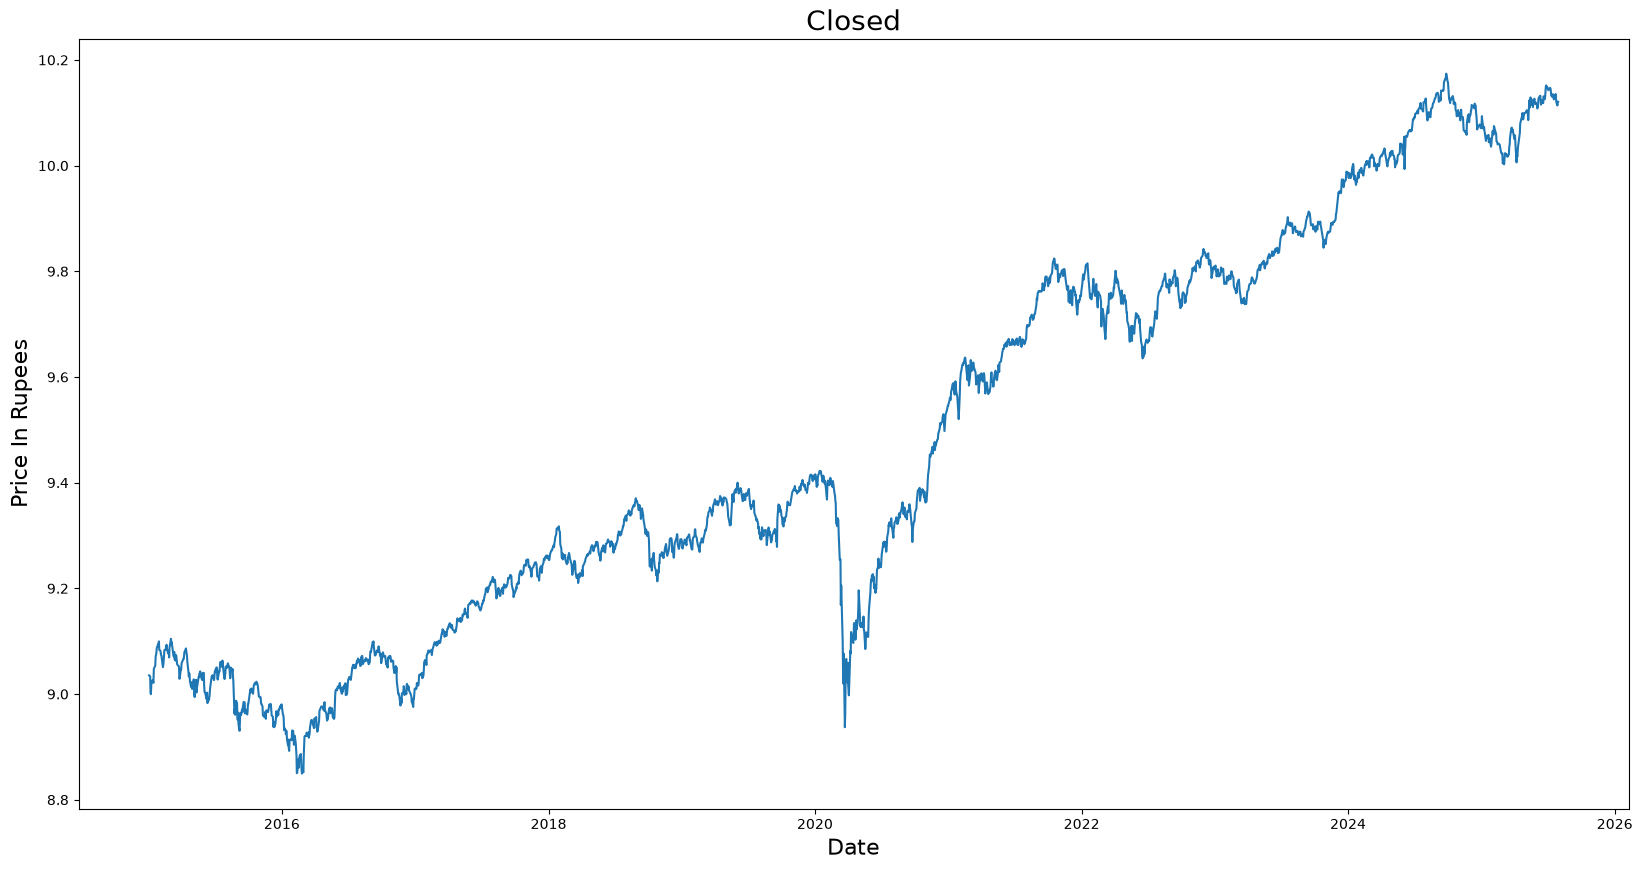

In [4]:
plt.figure(figsize=(20,10))
plt.plot(df2['close'])
plt.title('Closed', fontsize=20)
plt.ylabel('Price In Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

### ADF Test

In [5]:
def check_stationary(data):
    result = adfuller(data)
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    if result[1] <= 0.05:
        print('The data is stationary.')
    else:
        print('The data is not stationary.')

check_stationary(df2.close)

first_diffs = df2.close - df2.close.shift(1)

df2['FirstDifference'] = first_diffs
df2.dropna(inplace=True)

check_stationary(df2.FirstDifference)

ADF Statistic: -0.1904447986471731
p-value: 0.9396510292101689
The data is not stationary.
ADF Statistic: -14.13042922903765
p-value: 2.338930960419258e-26
The data is stationary.


### KPSS Test

In [6]:
from statsmodels.tsa.stattools import kpss
import pandas as pd

def kpss_test(series, **kw):

    statistic, p_value, n_lags, critical_values = kpss(series, **kw)

    # Format and print the results
    print(f'KPSS Statistic: {statistic}')
    print(f'P-Value: {p_value}')
    print(f'Number of Lags: {n_lags}')
    print('Critical Values:')
    for key, value in critical_values.items():
        print(f'   {key}: {value}')

    # Interpret the results
    if p_value < 0.05:
        print("\nConclusion: The series is NOT stationary (reject H0).")
    else:
        print("\nConclusion: The series IS stationary (fail to reject H0).")



In [7]:
print("--- KPSS Test on Original Log-Close Price ---")
kpss_test(df2['close'])

print("\n" + "="*40 + "\n")

# Test the first-differenced data
print("--- KPSS Test on First Difference ---")
kpss_test(df2['FirstDifference'].dropna())

--- KPSS Test on Original Log-Close Price ---
KPSS Statistic: 8.070761722720544
P-Value: 0.01
Number of Lags: 30
Critical Values:
   10%: 0.347
   5%: 0.463
   2.5%: 0.574
   1%: 0.739

Conclusion: The series is NOT stationary (reject H0).


--- KPSS Test on First Difference ---
KPSS Statistic: 0.0692059115091974
P-Value: 0.1
Number of Lags: 12
Critical Values:
   10%: 0.347
   5%: 0.463
   2.5%: 0.574
   1%: 0.739

Conclusion: The series IS stationary (fail to reject H0).


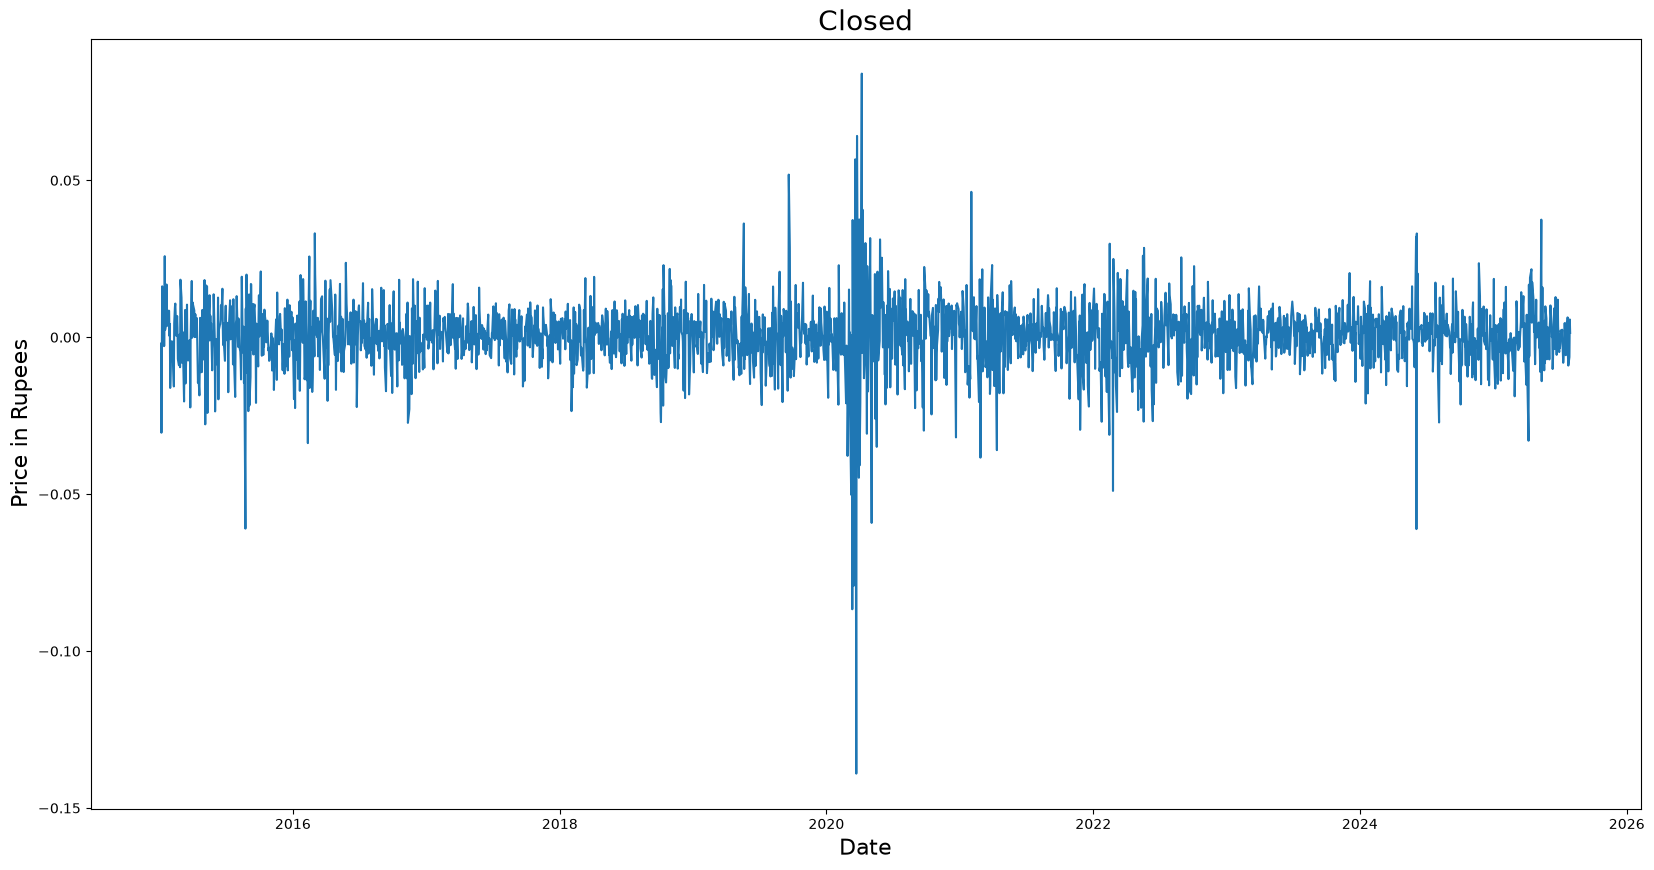

In [8]:
plt.figure(figsize=(20,10))
plt.plot(df2.FirstDifference)
plt.title('Closed', fontsize=20)
plt.ylabel('Price in Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

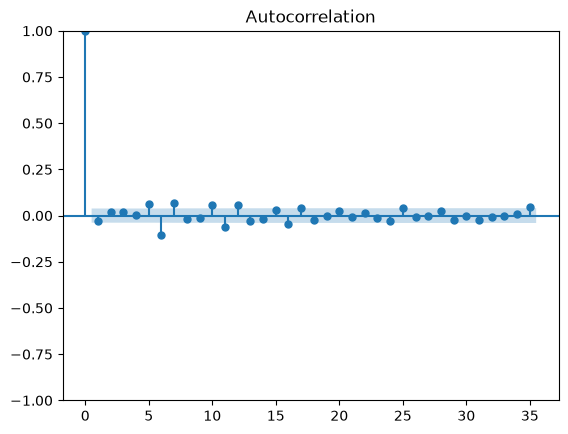

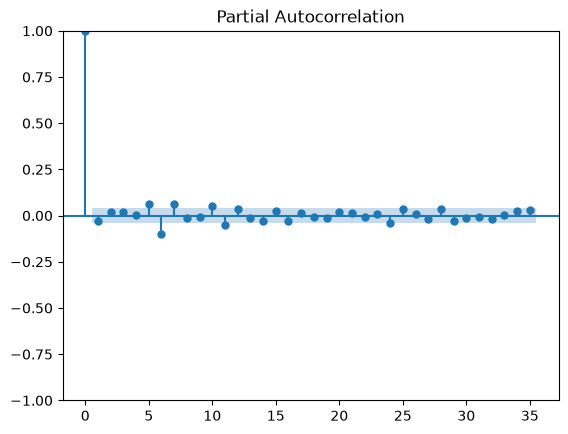

In [9]:
# Plotting ACF plot to choose value for MA

plot_acf(df2.FirstDifference)
plt.show()

# Plotting PACF plot to choose value for AR

plot_pacf(df2.FirstDifference)
plt.show()

### ARIMA Model

In [10]:
# Creating the ARIMA model and fitting the values

model = ARIMA(df2.FirstDifference.dropna(), order=(1,1,0))
result = model.fit()

fvalues = result.fittedvalues
result.summary()

residual = result.resid
residual = residual.cumsum()

In [11]:

a = df2.close - df2.FirstDifference
diff_results = residual + residual.shift(-1)
diff_results = diff_results + a

In [12]:
df1 = diff_results
df1.dropna(inplace=True)

# Normalizing the data

scaler = MinMaxScaler(feature_range=(0,1))
df1 = scaler.fit_transform(np.array(df1).reshape(-1,1))

In [13]:
# Defining the train and test data size

training_size=int(len(df1)*0.70)
test_size=len(df1)-training_size
train_data,test_data=df1[:training_size],df1[training_size:]

In [14]:
def create_dataset(dataset, time_step=60):
	dataX, dataY = [], []
	for i in range(len(dataset)-time_step-1):
		a = dataset[i:(i+time_step)]
		dataX.append(a)
		dataY.append(dataset[i + time_step])
	return np.array(dataX), np.array(dataY)

time_step = 60
X_train, y_train = create_dataset(train_data, time_step)
X_test, y_test = create_dataset(test_data, time_step)

In [15]:
X_train =X_train.reshape(X_train.shape[0],X_train.shape[1] , 1)
X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] , 1)

len(X_train), len(y_train), len(X_test), len(y_test)

(1760, 1760, 720, 720)

### LSTM Model

In [16]:
# Creating LSTM model

model=Sequential()
model.add(Input(shape=(X_train.shape[1],1)))
model.add(LSTM(64))
model.add(Dropout(0.3))
model.add(Dense(25))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam', metrics=['accuracy'])

In [17]:
# Summary for LSTM model

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,547 (72.45 KB)

 Trainable params: 18,547 (72.45 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)

Epoch 1/5


 1/28 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.0000e+00 - loss: 0.1201

 4/28 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0000e+00 - loss: 0.0851

 7/28 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0000e+00 - loss: 0.0545

10/28 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0000e+00 - loss: 0.0418

13/28 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0000e+00 - loss: 0.0367

... (48 outputs left out)

22/28 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0000e+00 - loss: 0.0013

25/28 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 6.2500e-04 - loss: 0.0014

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 5.6818e-04 - loss: 0.0014

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 5.6818e-04 - loss: 0.0014 - val_accuracy: 0.0014 - val_loss: 1.6913e-04


In [19]:
train_predict=model.predict(X_train)
test_predict=model.predict(X_test)

 1/55 ━━━━━━━━━━━━━━━━━━━━ 9s 174ms/step

 9/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step  

17/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

24/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

32/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

40/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

... (3 outputs left out)

10/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

18/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [20]:
mape_stock = mean_absolute_percentage_error(y_test,test_predict)
rmse_stock = np.sqrt(mean_squared_error(y_test,test_predict))
mase_stock = np.mean(np.abs(y_test - test_predict)) / np.mean(np.abs(pd.DataFrame(y_test).diff().dropna()))
print(f"NIFTY - MAPE: {mape_stock}, RMSE: {rmse_stock}, MASE: {mase_stock}")

NIFTY - MAPE: 0.011909794379493546, RMSE: 0.013005168972048852, MASE: 1.8684871837412305


In [21]:
final_test = pd.DataFrame(df2[1883:])
final_test['close'] = np.exp(final_test['close'])
final_test['test'] = np.exp(scaler.inverse_transform(test_predict))

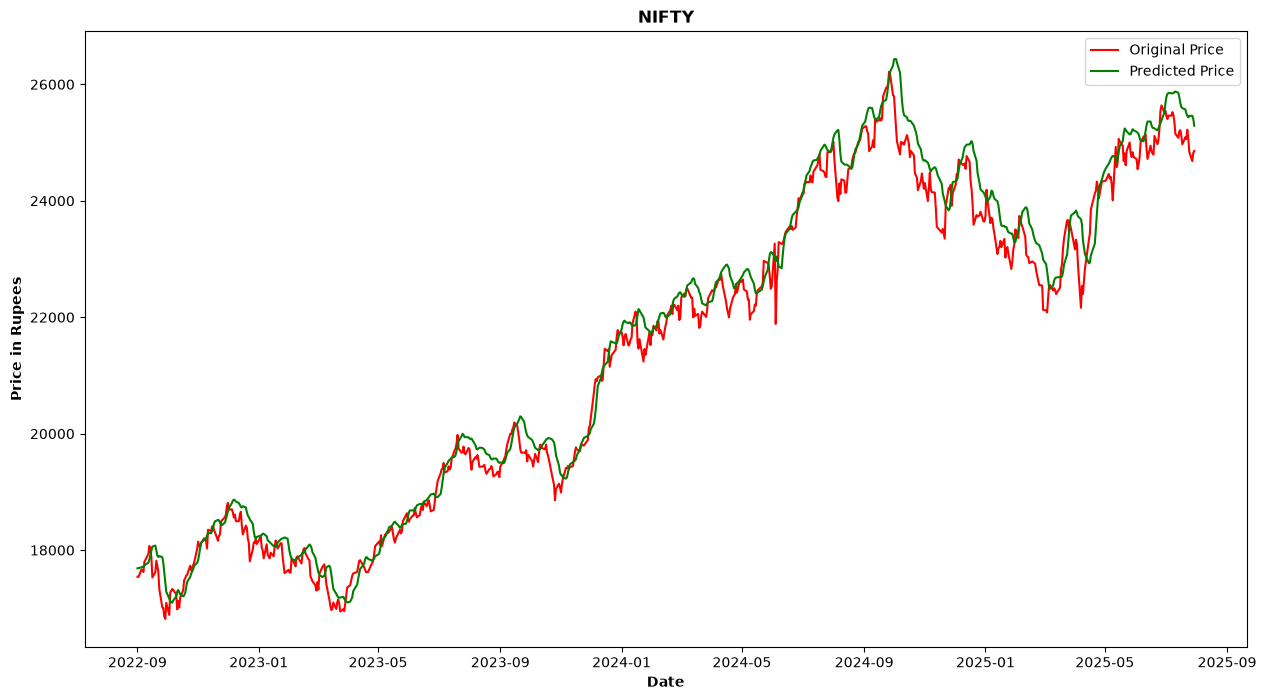

In [22]:
# Plotting the predictied price wrt original price of test

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('NIFTY', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()

### Bi-LSTM Model

In [23]:
# Build BiLSTM model
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout

model_bilstm = Sequential([
    Input(shape=(X_train.shape[1],1)),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(32,activation='tanh'),
    Dropout(0.3),
    Dense(1)  # Binary classification
])

# Compile the model
model_bilstm.compile(optimizer='adam', loss='mse')

model_bilstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model_bilstm.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)

Epoch 1/5


 1/28 ━━━━━━━━━━━━━━━━━━━━ 1:13 3s/step - loss: 0.1978

 4/28 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0975

 7/28 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0641

10/28 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0553

13/28 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0459

... (50 outputs left out)

21/28 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0045

24/28 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0045

27/28 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0045

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0045 - val_loss: 3.0890e-04


In [25]:
train_predict_bi=model_bilstm.predict(X_train)
test_predict_bi=model_bilstm.predict(X_test)

 1/55 ━━━━━━━━━━━━━━━━━━━━ 15s 291ms/step

 9/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step   

17/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

24/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

31/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

39/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

... (4 outputs left out)

 9/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 

17/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


In [26]:
mape_stock = mean_absolute_percentage_error(y_test,test_predict_bi)
rmse_stock = np.sqrt(mean_squared_error(y_test,test_predict_bi))
mase_stock = np.mean(np.abs(y_test - test_predict_bi)) / np.mean(np.abs(pd.DataFrame(y_test).diff().dropna()))
print(f"NIFTY - MAPE: {mape_stock}, RMSE: {rmse_stock}, MASE: {mase_stock}")

NIFTY - MAPE: 0.017108308870455297, RMSE: 0.017575680909347746, MASE: 2.690557217544093


In [27]:
final_test = pd.DataFrame(df2[1883:])
final_test['close'] = np.exp(final_test['close'])
final_test['test'] = np.exp(scaler.inverse_transform(test_predict))

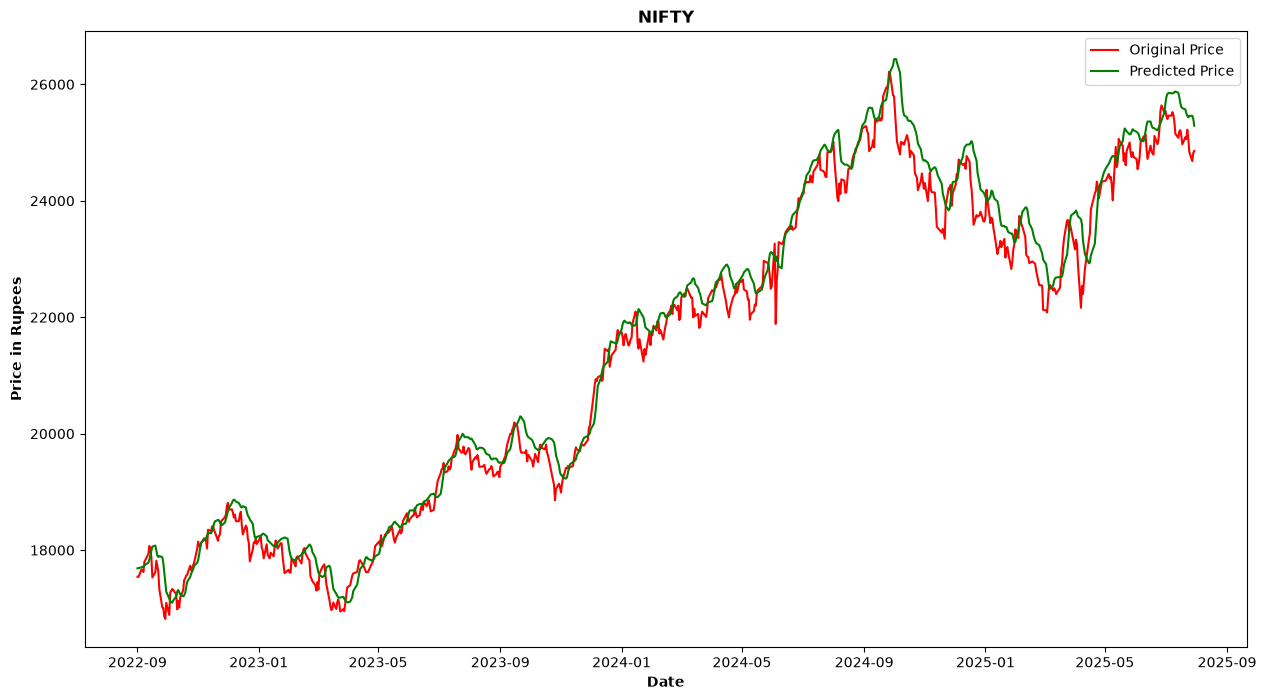

In [28]:
# Plotting the predictied price wrt original price of test

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('NIFTY', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()

### GRU Model

In [29]:
#Create GRU Model

from tensorflow.keras.layers import GRU, Dense, Dropout
model_gru = Sequential([
    Input(shape=(X_train.shape[1],1)),
    GRU(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='tanh'),
    Dense(1)  # single value prediction
])

model_gru.compile(optimizer='adam', loss='mse')
model_gru.summary()
model_gru.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)
train_predict_gru=model_gru.predict(X_train)
test_predict_gru=model_gru.predict(X_test)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


... (64 outputs left out)

11/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [30]:
mape_stock = mean_absolute_percentage_error(y_test,test_predict_gru)
rmse_stock = np.sqrt(mean_squared_error(y_test,test_predict_gru))
mase_stock = np.mean(np.abs(y_test - test_predict_gru)) / np.mean(np.abs(pd.DataFrame(y_test).diff().dropna()))
print(f"NIFTY - MAPE: {mape_stock}, RMSE: {rmse_stock}, MASE: {mase_stock}")

NIFTY - MAPE: 0.019430191410708033, RMSE: 0.01924826895859048, MASE: 3.142107029442825


In [31]:
final_test = pd.DataFrame(df2[1883:])
final_test['close'] = np.exp(final_test['close'])
final_test['test'] = np.exp(scaler.inverse_transform(test_predict))

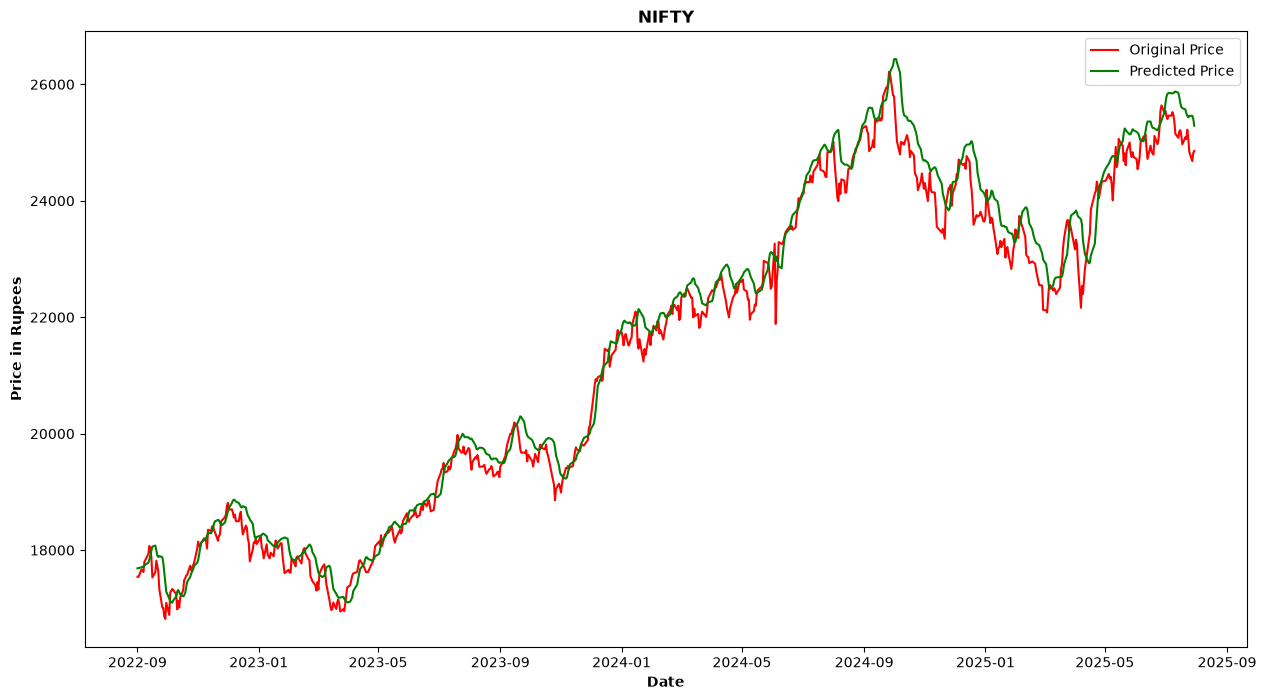

In [32]:
# Plotting the predictied price wrt original price of test

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('NIFTY', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()

### Deep GRU Model

In [33]:
#Deep GRU Architecture

model_dgru = Sequential([
    Input(shape=(X_train.shape[1],1)),
    GRU(64, return_sequences=True),  # 1st GRU layer
    Dropout(0.3),
    GRU(64, return_sequences=True),  # 2nd GRU layer
    Dropout(0.3),
    GRU(32, return_sequences=False),  # 3rd GRU layer (last RNN)
    Dropout(0.2),
    Dense(32, activation='tanh'),
    Dense(1)  # single value prediction
])

model_dgru.compile(optimizer='adam', loss='mse')
model_dgru.summary()

model_dgru.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)
train_predict_dgru=model_dgru.predict(X_train)
test_predict_dgru=model_dgru.predict(X_test)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 60, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 60, 64)         │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,321 (188.75 KB)

 Trainable params: 48,321 (188.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


... (157 outputs left out)

16/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


In [34]:
# Metrics
mape_stock = mean_absolute_percentage_error(y_test, test_predict_dgru)
mse_stock = mean_squared_error(y_test, test_predict_dgru)
rmse_stock = np.sqrt(mse_stock)

# Fixing MASE calculation using y_train (naive forecast based on previous value)
naive_forecast_error = np.mean(np.abs(np.diff(y_train.reshape(-1))))  # If y_train is a NumPy array
# If y_train is a Pandas Series or DataFrame, use: y_train.values.reshape(-1)

mase_stock = np.mean(np.abs(y_test - test_predict_dgru)) / naive_forecast_error

# Print results
print(f"Stock - MAPE: {mape_stock:.4f}, MSE: {mse_stock:.4f}, RMSE: {rmse_stock:.4f}, MASE: {mase_stock:.4f}")

Stock - MAPE: 0.0162, MSE: 0.0003, RMSE: 0.0170, MASE: 1.9192


In [35]:
final_test = pd.DataFrame(df2[1883:])
final_test['close'] = np.exp(final_test['close'])
final_test['test'] = np.exp(scaler.inverse_transform(test_predict_dgru))

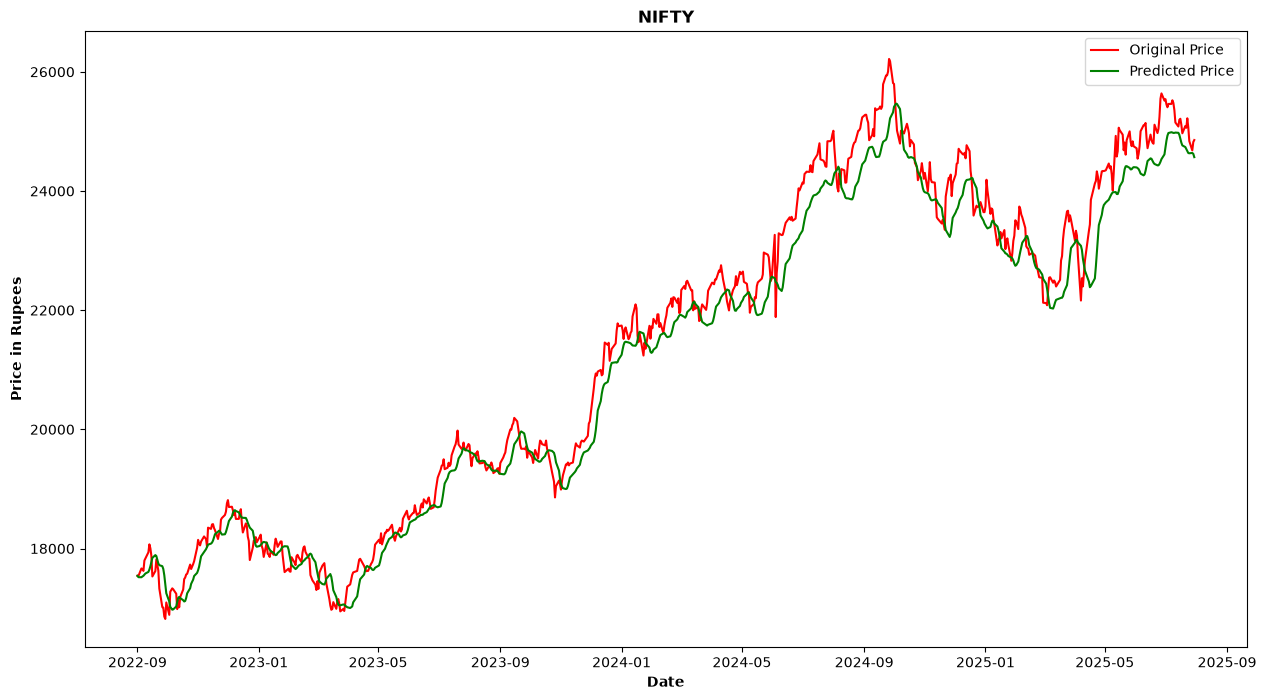

In [36]:
# Plotting the predictied price wrt original price of test

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('NIFTY', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()